# Extraction de Keywords

In [1]:
import os
import yake

In [2]:
# Instantier l'extracteur de mots clés
kw_extractor = yake.KeywordExtractor(lan="fr", top=50)
kw_extractor

In [3]:
# Lister les Fichiers
data_path = "../../data/txt/"
files = [f for f in os.listdir(data_path) if f.endswith('.txt')]

In [4]:
#tp
year = "1960"

In [5]:
#tp
files_year = [f for f in files if f.split('_')[2].startswith(year)]

In [6]:
# Imprimer le nombre de fichiers identifiés
len(files)

7936

In [7]:

len(files_year)

100

In [8]:
files_year[:10]

['KB_JB838_1960-10-30_01-00007.txt',
 'KB_JB838_1960-04-20_01-00016.txt',
 'KB_JB838_1960-01-22_01-00015.txt',
 'KB_JB838_1960-03-25_01-00020.txt',
 'KB_JB838_1960-09-27_01-00009.txt',
 'KB_JB838_1960-12-02_01-00004.txt',
 'KB_JB838_1960-03-04_01-00010.txt',
 'KB_JB838_1960-01-12_01-00011.txt',
 'KB_JB838_1960-06-01_01-00011.txt',
 'KB_JB838_1960-03-16_01-00007.txt']

In [9]:
# Choisir un fichier
this_file = files_year[0]
this_file

'KB_JB838_1960-10-30_01-00007.txt'

In [10]:
# Récupérer le texte du fichier
text = open(os.path.join(data_path, this_file), 'r', encoding='utf-8').read()
text[:500]

't DIMANCHE 30 et LUNDI 31 OCTOBRE 1960 LE SOIR Evénement inattendu mais encourageant en football : double victoire belge sur les Belgique bat Hongrie: 2-1 Nos joueurs ont manœuvré avec autant d’habileté qu’à Stockholm, mais, cette fois, ils ont shooté Il y a auatre ans, 72.000 personnes sc pressaient au stade du Heysel pour assister au dernier Belgique - Hongrie. Cette foule bondit de joie « l’issue de la partie parce que les nôtres remportaient la victoire (5-4) Il est curieux de constater qu’e'

In [11]:
# Extraire les mots clés de ce texte
keywords = kw_extractor.extract_keywords(text)
keywords

[('SOIR Evénement inattendu', np.float64(0.001439946218232747)),
 ('SOIR Evénement', np.float64(0.005016137525527277)),
 ('hongrois', np.float64(0.006721831616013241)),
 ('but hongrois', np.float64(0.007775631192626479)),
 ('but', np.float64(0.007930787288156412)),
 ('Van Himst', np.float64(0.008223895020170385)),
 ('jeu', np.float64(0.009313711982992662)),
 ('match', np.float64(0.010008479989656193)),
 ('belge', np.float64(0.010918886290466473)),
 ('belges', np.float64(0.010918886290466473)),
 ('but belge', np.float64(0.011650872916455139)),
 ('fut', np.float64(0.012180598282675472)),
 ('Belgique bat Hongrie', np.float64(0.016049234184904074)),
 ('Belgique', np.float64(0.01610960154743106)),
 ('double victoire belge', np.float64(0.01828089661276146)),
 ('l’équipe belge', np.float64(0.018900951948485907)),
 ('Evénement inattendu', np.float64(0.019929494137577764)),
 ('Hongrie', np.float64(0.021522280488466664)),
 ('but belge Cooromans', np.float64(0.023154180333290548)),
 ('l’équipe', 

In [12]:
# Ne garder que les bigrammes
kept = []
for kw, score in keywords:
    words = kw.split()
    if len(words) == 2:
        kept.append(kw)
kept

['SOIR Evénement',
 'but hongrois',
 'Van Himst',
 'but belge',
 'l’équipe belge',
 'Evénement inattendu',
 'Jean Nicolay',
 'défenseurs hongrois',
 'Diables rouges']

In [14]:
for f in sorted(files_year)[:100]:
    text = open(os.path.join(data_path, f), 'r', encoding="utf-8").read()
    keywords = kw_extractor.extract_keywords(text)
    kept = []
    for kw, score in keywords:
        words = kw.split()
        if len(words) == 2:
            kept.append(kw)
    print(f"{f} mentions these keywords: {', '.join(kept)}...")

KB_JB838_1960-01-10_01-00018.txt mentions these keywords: Agence Rossel, l’Agence Rossel, Ecrire Agence, Faire offre, Rossel num, IMPORTANTE SOCIETE, Importante firme, BRUXELLES CHERCHE, Importante société, Firme Importante, curriculum vitae, offre manuscrite, vltae Agence...
KB_JB838_1960-01-12_01-00011.txt mentions these keywords: Van den, Van der, classements officiels, Coq Anglais, Van Houtte, Country Club, Léopold Club, Van Blesebroeck, Astrld Club, Van Belle, Baudouin Club...
KB_JB838_1960-01-13_01-00009.txt mentions these keywords: VAN LOOY, Van Stcenbergen, Rik Van, DIVISION III, Fort Jaco, Grand Prix, grand temps, Dimanche division, dimanche dernier...
KB_JB838_1960-01-21_01-00014.txt mentions these keywords: chemise lavée, CHEMISES LAVÉES, Office Propriétaires, Propriétaires Tél, WATERLOO TéL, maison rapport, belle maison, PRIX TARIF, francs Office, bonne maison...
KB_JB838_1960-01-22_01-00015.txt mentions these keywords: LOUER App, Pastilles Antibiotiques, FER FORGE, spac. a

# Nuages de mots

In [15]:
from collections import Counter
from wordcloud import WordCloud
import os
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
from IPython.display import Image

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/khadija/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [16]:
#tp
# Stopwords (Idem que dans s1)
sw = stopwords.words("french")
sw += ["les", "plus", "cette", "fait", "faire", "être", "deux", "comme", "dont", "tout",
       "ils", "bien", "sans", "peut", "tous", "après", "ainsi", "donc", "cet", "sous",
       "celle", "entre", "encore", "toutes", "pendant", "moins", "dire", "cela", "non",
       "faut", "trois", "aussi", "dit", "avoir", "doit", "contre", "depuis", "autres",
       "van", "het", "autre", "jusqu", "ville", "rossel", "dem"]

#tour 1 : 
sw += ["toujours","chez", "dès", "puis","point", "bon", "quelques", "plusieurs",
       "leurs", "vers", "celui", "quelque", "rien", "près", "alors", "avant", 
       "également", "trop", "peu", "car", "ceux", "début", "toute", "nouveau",
       "fois"]

#tour 2 : 
sw += ["très", "déjà","cependant","etc", "jamais", "pet", "prés", "faç", "pers", "lux",
       "enf", "référ", "bur", "bel", "mat","conf", "fem", "rem", "réf", "jne", "mén",
         "gar", "mod", "trav" ]

#tour 3 : 
sw += ["louer", "appart", "demande", "avenue", "offre", "tel", "maison", "villa",
       "vente", "téleph", "elles", "quand", "com", "tant", "midi", "culs","lundi", 
       "mardi","seulement","rue", "jeudi", "cherche", "voiture", "jour", "année",
        "semaine", "quatre", "vendredi", "mercredi", "certains"]

#tour 4 : 
sw += ["chaque", "ans", "janvier", "mars", "années", "int", "téléphone", "selon",
       "février", "samedi", "temps", "décembre", "prix", "cinq", "sem", "octobre",
       "dimanche","téléph", "juillet", "mois", "heures", "septembre", "heure", "avril",
          ]
#tour 5 : 
sw += ["jours", "sept", "âge", "ventes", "age", "ouvr", "aôut", "six", "aven", "assez",
        "café" ]

#tour 6 : 
sw += ["enfin", "petit", "grand", "matin", "nuit","vis", "lors","août", "beaucoup",
        "grande", "belle", "beau" ] 

#tour 7 : 
sw += ["vend", "serveuse", "ouvrier", "dactylo", "occasion", "voici", "demi", " prendre", 
       "vient", "chf", "gros", "servante","petite", "garage", "bonne", "ixelles", "uccle",
       "étage", "devant", "voir", "vitae", "notamment", "vie", "anderlecht", "chaussée",
       "agence"]

#tour 8 : 
sw += ["donné", "eau", "bilingue", "sait", "grands", "mai", "parce", "hui", "cher", "auto",
      "vue", "tête","dame", "parmi", "présenter", "jard","serv", "mètres", "main", "bons",
       "laquelle", "juin", "effet", "journée","lieu", "seul", "mieux", "adresser", "nom",
        "ecrire", "tél", "app", "question", "novembre", "dernière" , "première", "troisième",
        "fort", "haut", "soir" ]

#tour 9 : 
sw += ["courant", "compte", "neuf", "points", "deuxième", "prendre", "radio", "cuis", "hôtel", "plan",
       "demeurant", "chambre", "hall", "nombre", "série", "max", "moment", "num", "sam", "feu",
       "nord", "sud", "brux", "ena", "cours", "part","opel", "parc", "serie", "fit", "fin", "terrain",
       "bonnes", "raison", "quart", "mer", "possible", "rez", "mise", "mettre", "reste", " bruxelles",
       "porte", "entrée", "mis", "pris", "dernier"  ]


#tour 10 : 
sw += ["sup", "valeur", "terr", "mme", "femme", "partir", "pièces", "salle", "seule", "ici", "ailleurs", 
"surtout", "minutes", "mal", "souvent", "suite", "cause", "bas", "aucun", "théâtre", "aucun", "emploi",
"homme", "office", "références", "fils", "quartier", "nouvelle", "coup", "comm", "repos", "dos", "personne",
"sens", "but", "new", "aide", "dames", "tard", "mari", "confort", "départ", "fille", "enfants", "cour", "mutuel",
"grâce", "présent", "vendre", "semble", "ter", "bat", "bois", "aujourd", "doute", "sal", "bruxelles" ] 

#tour 11 : 
sw += ["achete", "net", "musique", "den", "satisfaction", "fiat", "pied", "tandis", "autant", "pourrait", "nombreux",
"environ", "reprise", "beaux", "haute", "devait", "problème", "hôpital", "nouvelles", "mari", "tonnes", "avis", "vit",
"luxe", "mesure", "bureau", "air", "actuellement", "importante", "façon", "terre", "monsieur", "côté", "action", "confort"]

#tour 12 : 
sw += ["con", "face", "personnes", "réunion", "brabant", "demandé", "prochain", "blessé", "prêt", "esprit", "urgent", "finale", 
"quant", "peine", "enfant", "produits", "agit", "corps", "coin", "lot", "salaire", "bureau", "seconde", "lots", "loin", "cap",
"personnel", "pourquoi", "long", "plein", "notaire", "cas", "apprenti", "jeune", "divers", "francs", "forme", "stable", "neuve",
 "cent" ]


sw = set(sw)





In [19]:
#tp
year ="1960"

In [20]:
# Lister les fichiers de cette année
data_path = '../../data'
txt_path = '../../data/txt'
txts = [f for f in os.listdir(txt_path) if os.path.isfile(os.path.join(txt_path, f)) and str(year) in f]
len(txts)

100

In [21]:
# Stocker le contenu de ces fichiers dans une liste
content_list = []
for txt in txts:
    with open(os.path.join(txt_path, txt), 'r', encoding='utf-8') as f:
        content_list.append(f.read())

In [22]:
# Compter le nombre d'éléments (=fichiers) dans la liste
len(content_list)

100

In [23]:
# Imprimer les 200 premiers caractères du contenu du premier fichier
content_list[0][0:200]

't DIMANCHE 30 et LUNDI 31 OCTOBRE 1960 LE SOIR Evénement inattendu mais encourageant en football : double victoire belge sur les Belgique bat Hongrie: 2-1 Nos joueurs ont manœuvré avec autant d’habile'

In [24]:
# Ecrire tout le contenu dans un fichier temporaire
temp_path = '../../data/tmp'
if not os.path.exists(temp_path):
    os.mkdir(temp_path)
with open(os.path.join(temp_path, f'{year}.txt'), 'w', encoding='utf-8') as f:
    f.write(' '.join(content_list))

In [25]:
# Imprimer le contenu du fichier et constater les "déchets"
with open(os.path.join(temp_path, f'{year}.txt'), 'r', encoding='utf-8') as f:
    before = f.read()

before[:500]

't DIMANCHE 30 et LUNDI 31 OCTOBRE 1960 LE SOIR Evénement inattendu mais encourageant en football : double victoire belge sur les Belgique bat Hongrie: 2-1 Nos joueurs ont manœuvré avec autant d’habileté qu’à Stockholm, mais, cette fois, ils ont shooté Il y a auatre ans, 72.000 personnes sc pressaient au stade du Heysel pour assister au dernier Belgique - Hongrie. Cette foule bondit de joie « l’issue de la partie parce que les nôtres remportaient la victoire (5-4) Il est curieux de constater qu’e'

In [26]:
def clean_text(year, folder=None):
    if folder is None:
        input_path = f"{year}.txt"
        output_path = f"{year}_clean.txt"
    else:
        input_path = f"{folder}/{year}.txt"
        output_path = f"{folder}/{year}_clean.txt"
    output = open(output_path, "w", encoding='utf-8')
    with open(input_path, 'r', encoding='utf-8') as f:
        text = f.read()
        words = nltk.wordpunct_tokenize(text)
        kept = [w.upper() for w in words if len(w) > 2 and w.isalpha() and w.lower() not in sw]
        kept_string = " ".join(kept)
        output.write(kept_string)
    return f'Output has been written in {output_path}!'

In [27]:
clean_text(year, folder=temp_path)

'Output has been written in ../../data/tmp/1960_clean.txt!'

In [28]:
# Vérifier le résultat
with open(os.path.join(temp_path, f'{year}_clean.txt'), 'r', encoding='utf-8') as f:
    after = f.read()

after[:500]

'EVÉNEMENT INATTENDU ENCOURAGEANT FOOTBALL DOUBLE VICTOIRE BELGE BELGIQUE HONGRIE JOUEURS MANŒUVRÉ HABILETÉ STOCKHOLM SHOOTÉ AUATRE PRESSAIENT STADE HEYSEL ASSISTER BELGIQUE HONGRIE FOULE BONDIT JOIE ISSUE PARTIE NÔTRES REMPORTAIENT VICTOIRE CURIEUX CONSTATER PHASES SIMILAIRES OFFERTE NÔTRES HASARD MALADRESSE DÉFENSEURS HONGROIS CROYONS DEMIS AILE TIN RENT BESOGNE DÉFENSIVE BASE MOUVEMENTS ATTAQUE ATTAQUES JEU ASSISTA STOCKMAN LIPPENS DEVANCÉS DÉFENSEURS HONGROIS PRÉCIPITÉS ENSEMBLE RENVOYER BALL'

In [29]:
frequencies = Counter(after.split())
print(frequencies.most_common(10))

[('PLACE', 412), ('ECR', 394), ('BELGIQUE', 346), ('BELGE', 333), ('CONGO', 294), ('SERVICE', 277), ('PAYS', 277), ('ANVERS', 270), ('JEAN', 258), ('TRAVAIL', 251)]


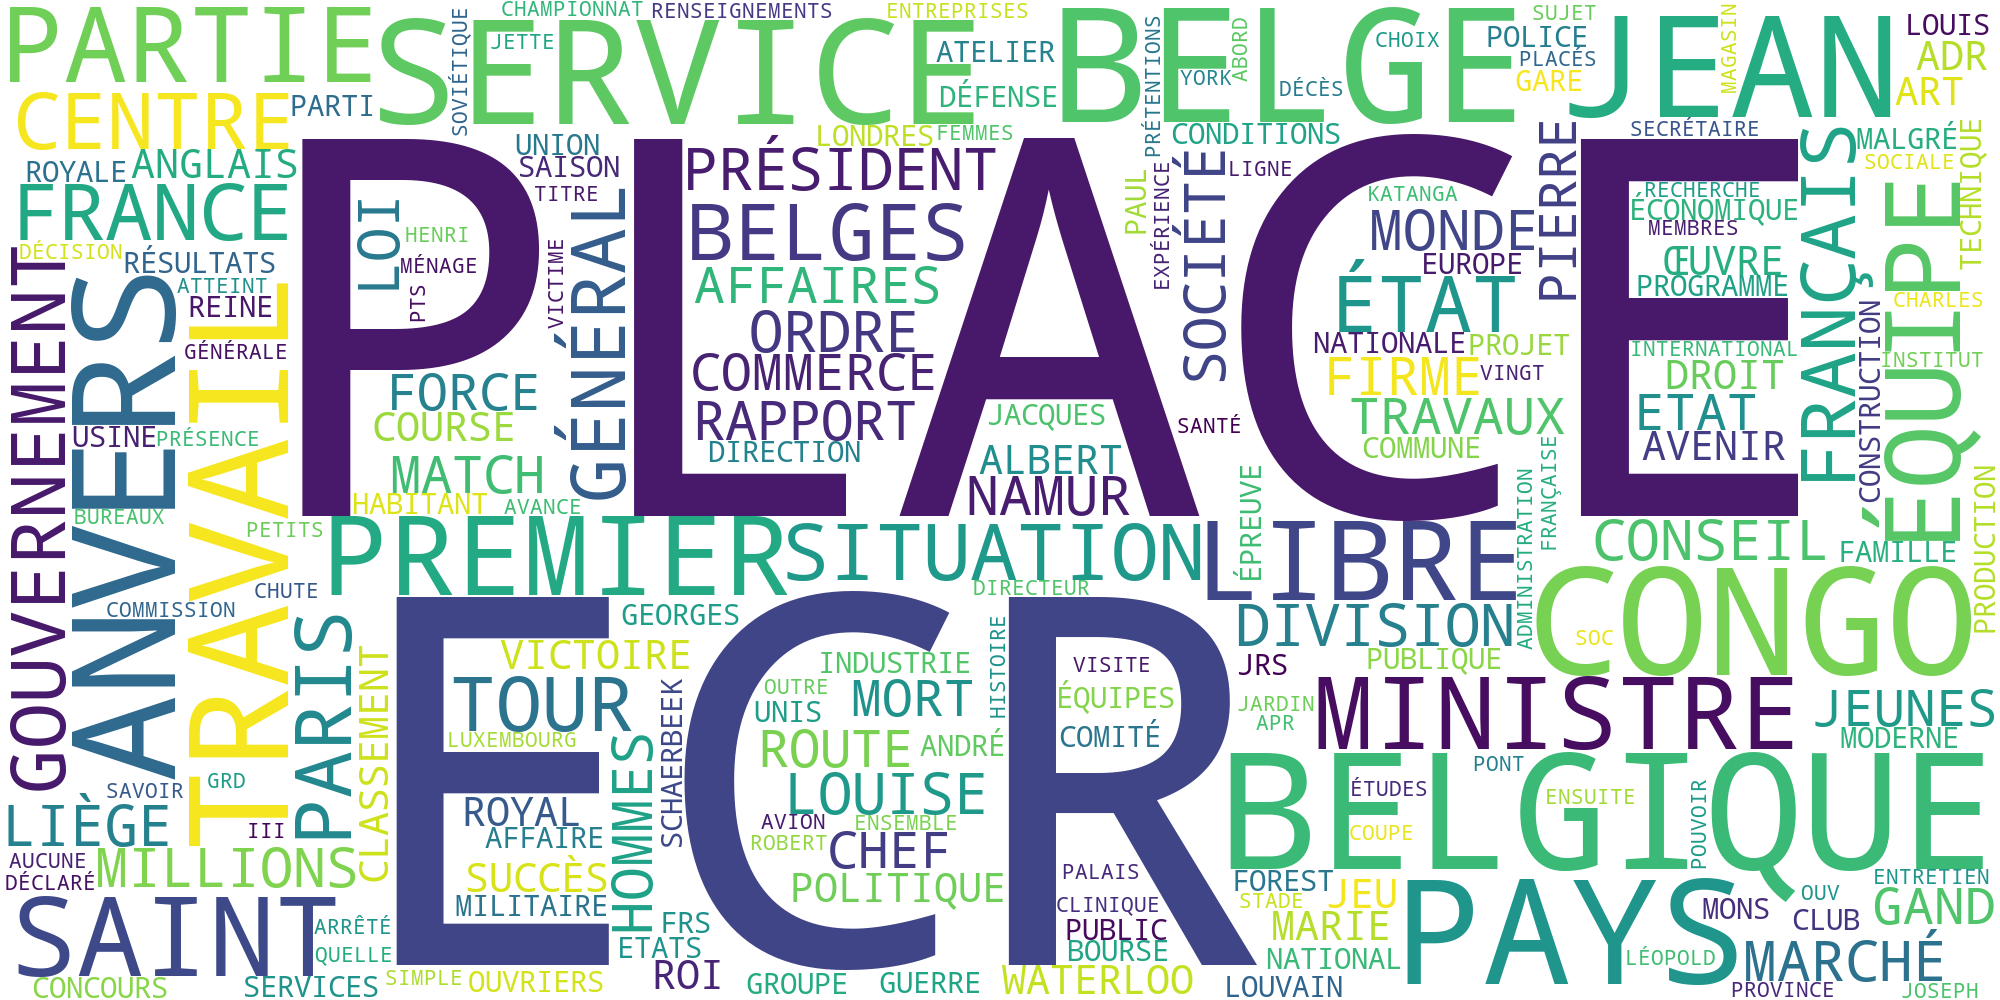

In [30]:
cloud = WordCloud(width=2000, height=1000, background_color='white').generate_from_frequencies(frequencies)
cloud.to_file(os.path.join(temp_path, f"{year}.png"))
Image(filename=os.path.join(temp_path, f"{year}.png"))

# Reconnaissance d'entités nommées 

In [31]:
from collections import defaultdict
import spacy
from spacy.lang.fr.examples import sentences

In [32]:
nlp = spacy.load('fr_core_news_md')

In [33]:
#tp
year ="1960"

In [34]:
# Lister les fichiers de cette année
data_path = '../../data'
txt_path = '../../data/txt'
txts = [f for f in os.listdir(txt_path) if os.path.isfile(os.path.join(txt_path, f)) and str(year) in f]
len(txts)

100

In [35]:
# Stocker le contenu de ces fichiers dans une liste
content_list = []
for txt in txts:
    with open(os.path.join(txt_path, txt), 'r', encoding='utf-8') as f:
        content_list.append(f.read()) 

In [36]:
# Charger le texte
text = ' '.join(content_list)
nlp.max_length = len(text) + 1000
len(text)

3338805

In [37]:
%%time
# Traiter le texte
doc = nlp(text)

CPU times: user 1min 48s, sys: 17.5 s, total: 2min 5s
Wall time: 2min 39s


In [38]:
# Compter les entités
people = defaultdict(int)
for ent in doc.ents:
    if ent.label_ == "PER" and len(ent.text) > 3:
        people[ent.text] += 1

In [39]:
# Trier et imprimer

sorted_people = sorted(people.items(), key=lambda kv: kv[1], reverse=True)

for person, freq in sorted_people[:50]:
    print(f"{person} apparait {freq} fois dans le corpus")

Rossel apparait 424 fois dans le corpus
culs apparait 76 fois dans le corpus
Ecrire Ag apparait 55 fois dans le corpus
Louise apparait 54 fois dans le corpus
Van Looy apparait 40 fois dans le corpus
Albert apparait 37 fois dans le corpus
Marie apparait 36 fois dans le corpus
curr apparait 35 fois dans le corpus
trav apparait 34 fois dans le corpus
- Tél apparait 32 fois dans le corpus
Agence Rossel apparait 30 fois dans le corpus
Jean apparait 29 fois dans le corpus
Bonne apparait 27 fois dans le corpus
O. N. U. apparait 27 fois dans le corpus
Jard apparait 22 fois dans le corpus
Robert apparait 22 fois dans le corpus
M. Khrouchtchev apparait 22 fois dans le corpus
Reine apparait 22 fois dans le corpus
général de Gaulle apparait 21 fois dans le corpus
Roger apparait 20 fois dans le corpus
curric apparait 20 fois dans le corpus
Janssens apparait 19 fois dans le corpus
A. P. apparait 19 fois dans le corpus
Monsieur apparait 19 fois dans le corpus
Molière apparait 18 fois dans le corpus
B

In [40]:
# lieux
places = defaultdict(int)
for ent in doc.ents:
    if ent.label_ == "LOC" and len(ent.text) > 3:
        places[ent.text] += 1

In [41]:
# Trier et imprimer

sorted_places = sorted(places.items(), key=lambda kv: kv[1], reverse=True)

for places, freq in sorted_places[:50]:
    print(f"{places} apparait {freq} fois dans le corpus")

Bruxelles apparait 562 fois dans le corpus
Brux apparait 231 fois dans le corpus
Belgique apparait 191 fois dans le corpus
Congo apparait 177 fois dans le corpus
Téléph apparait 175 fois dans le corpus
Anvers apparait 139 fois dans le corpus
Paris apparait 103 fois dans le corpus
Liège apparait 95 fois dans le corpus
Etat apparait 89 fois dans le corpus
Belges apparait 70 fois dans le corpus
Gand apparait 68 fois dans le corpus
Agence Rossel apparait 66 fois dans le corpus
Anderlecht apparait 60 fois dans le corpus
France apparait 56 fois dans le corpus
Namur apparait 56 fois dans le corpus
Etats-Unis apparait 55 fois dans le corpus
Londres apparait 52 fois dans le corpus
Uccle apparait 49 fois dans le corpus
Katanga apparait 49 fois dans le corpus
Mons apparait 48 fois dans le corpus
Louvain apparait 47 fois dans le corpus
Ixelles apparait 44 fois dans le corpus
Schaerbeek apparait 42 fois dans le corpus
Léopoldville apparait 42 fois dans le corpus
Allemagne apparait 38 fois dans le c

In [42]:
# organisations
organisations = defaultdict(int)
for ent in doc.ents:
    if ent.label_ == "ORG" and len(ent.text) > 3:
        organisations[ent.text] += 1

In [43]:
# Trier et imprimer

sorted_organisations = sorted(organisations.items(), key=lambda kv: kv[1], reverse=True)

for organisations, freq in sorted_organisations[:50]:
    print(f"{organisations} apparait {freq} fois dans le corpus")

Conseil apparait 53 fois dans le corpus
Agence Rossel apparait 37 fois dans le corpus
trav apparait 36 fois dans le corpus
Agence Rossel num apparait 30 fois dans le corpus
Inst apparait 27 fois dans le corpus
exlg apparait 25 fois dans le corpus
Standard apparait 22 fois dans le corpus
Parlement apparait 22 fois dans le corpus
Chambre apparait 21 fois dans le corpus
OPEL apparait 20 fois dans le corpus
EMPLOYEE apparait 19 fois dans le corpus
Benelux apparait 19 fois dans le corpus
Racing apparait 17 fois dans le corpus
Blancs apparait 17 fois dans le corpus
PARC apparait 17 fois dans le corpus
O.N.U. apparait 16 fois dans le corpus
CREDIT apparait 16 fois dans le corpus
Mutuel apparait 15 fois dans le corpus
FIAT apparait 15 fois dans le corpus
Téléphone apparait 14 fois dans le corpus
Firme apparait 14 fois dans le corpus
GALERIES apparait 13 fois dans le corpus
Nations Unies apparait 13 fois dans le corpus
Reuter apparait 13 fois dans le corpus
Fiat apparait 12 fois dans le corpus


# Sentiment analysis 



In [44]:
from textblob import Blobber
from textblob_fr import PatternTagger, PatternAnalyzer

In [45]:
tb = Blobber(pos_tagger=PatternTagger(), analyzer=PatternAnalyzer())

def get_sentiment(input_text):
    blob = tb(input_text)
    polarity, subjectivity = blob.sentiment
    polarity_perc = f"{100*abs(polarity):.0f}"
    subjectivity_perc = f"{100*subjectivity:.0f}"
    if polarity > 0:
        polarity_str = f"{polarity_perc}% positive"
    elif polarity < 0:
        polarity_str = f"{polarity_perc}% negative"
    else:
        polarity_str = "neutral"
    if subjectivity > 0:
        subjectivity_str = f"{subjectivity_perc}% subjective"
    else:
        subjectivity_str = "perfectly objective"
    print(f"This text is {polarity_str} and {subjectivity_str}.")

In [46]:
get_sentiment("D’autre part, les nouvelles reçues de Malaisie sont encourageantes.")

This text is neutral and 12% subjective.


In [47]:
get_sentiment("A Liège, une partie des remparts s’écroula du côté de Saint-Jean-du-Mont.")

This text is neutral and perfectly objective.


In [48]:
get_sentiment("M. Lekeux affirma souffrir de pertes de mémoire et avoir absorbé un tube de somnifère, jeudi, dans le but d’attenter à ses jours.")

This text is 30% positive and 60% subjective.


In [49]:
get_sentiment("L’insuffisance de Vitamine P.P dans l’alimentation est à l’origine de troubles de l’organisme, se traduisant par un manque d’appétit, mauvaise digestions, constipation, migraines, maladies de peau (boutons, eczéma, herpès, etc …).")

This text is 40% negative and 80% subjective.


In [50]:
get_sentiment("L’approvisionnement des usines ne soulève pour le moment aucun problème.")

This text is neutral and perfectly objective.


In [51]:
get_sentiment("Les achats d’acier se sont quelque peu ralenti, car la clientèle ne veut pas constituer des stocks trop importants.")

This text is 8% positive and 24% subjective.


In [52]:
get_sentiment("Le conseil estime que les perspectives sont favorables.")

This text is 50% positive and 60% subjective.


In [53]:
get_sentiment("M. Machtens (soc.) regrette qu’aucune mesure fondamentale n’ait encore été prise pour redresser la situation financière des communes.")

This text is 8% positive and 10% subjective.


In [54]:
get_sentiment("Les résultats de l'exercice clos le 31 décembre 1959 sont très satisfaisants.")

This text is 35% positive and 55% subjective.


In [55]:
get_sentiment("La production et la consommation d'énergie, ne cessent de se développer.")

This text is neutral and perfectly objective.


In [56]:
!uv pip install sentencepiece
!uv pip install "transformers>=5.19.0"
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from transformers import pipeline

Using Python 3.13.15 environment at: /Users/khadija/tac/.venv
Checked 1 package in 63ms
Using Python 3.13.15 environment at: /Users/khadija/tac/.venv
Checked 1 package in 19ms


/Users/khadija/tac/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1116 18:20:57.442000 13458 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


In [57]:
tokenizer = AutoTokenizer.from_pretrained("philschmid/pt-tblard-tf-allocine")
model = AutoModelForSequenceClassification.from_pretrained("philschmid/pt-tblard-tf-allocine")

sentiment_analyser = pipeline('sentiment-analysis', model=model, tokenizer=tokenizer)

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 48574.27it/s]


In [58]:
sentiment_analyser("D’autre part, les nouvelles reçues de Malaisie sont encourageantes.")

[{'label': 'NEGATIVE', 'score': 0.5480218529701233}]

In [59]:
sentiment_analyser("A Liège, une partie des remparts s’écroula du côté de Saint-Jean-du-Mont.")

[{'label': 'NEGATIVE', 'score': 0.6743627786636353}]

In [60]:
sentiment_analyser("M. Lekeux affirma souffrir de pertes de mémoire et avoir absorbé un tube de somnifère, jeudi, dans le but d’attenter à ses jours.")

[{'label': 'NEGATIVE', 'score': 0.8930574059486389}]

In [61]:
sentiment_analyser("L’insuffisance de Vitamine P.P dans l’alimentation est à l’origine de troubles de l’organisme, se traduisant par un manque d’appétit, mauvaise digestions, constipation, migraines, maladies de peau (boutons, eczéma, herpès, etc …).")

[{'label': 'NEGATIVE', 'score': 0.5578598380088806}]

In [62]:
sentiment_analyser("L’approvisionnement des usines ne soulève pour le moment aucun problème.")

[{'label': 'NEGATIVE', 'score': 0.9586700201034546}]

In [63]:
sentiment_analyser("Les achats d’acier se sont quelque peu ralenti, car la clientèle ne veut pas constituer des stocks trop importants.")

[{'label': 'NEGATIVE', 'score': 0.6910978555679321}]

In [64]:
sentiment_analyser("Le conseil estime que les perspectives sont favorables.")

[{'label': 'POSITIVE', 'score': 0.5374158620834351}]

In [65]:
sentiment_analyser("M. Machtens (soc.) regrette qu’aucune mesure fondamentale n’ait encore été prise pour redresser la situation financière des communes.")

[{'label': 'NEGATIVE', 'score': 0.850890576839447}]

In [66]:
sentiment_analyser("Les résultats de l'exercice clos le 31 décembre 1959 sont très satisfaisants.")

[{'label': 'POSITIVE', 'score': 0.725140392780304}]

In [67]:
sentiment_analyser("La production et la consommation d'énergie, ne cessent de se développer.")

[{'label': 'POSITIVE', 'score': 0.5958101749420166}]